## Imports

Apenas NumPy, Matplotlib e skimage (somente para carregar a imagem de exemplo). O OpenCV não é importado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

## Imagem de exemplo

`data.camera()` já é uma imagem em escala de cinza (512 x 512, `uint8`, valores de 0 a 255).

Formato: (512, 512)
Tipo: uint8
Mínimo e máximo: 0 255


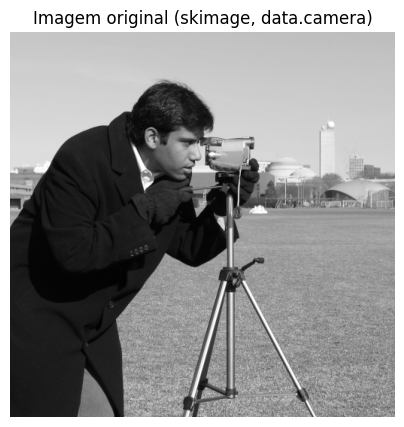

In [2]:
img = data.camera()

print('Formato:', img.shape)
print('Tipo:', img.dtype)
print('Mínimo e máximo:', img.min(), img.max())

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Imagem original (skimage, data.camera)')
plt.axis('off')
plt.show()

##  Convolução manual

A função `convolucao_manual` faz o seguinte:

1. Completa as bordas da imagem com `np.pad` no modo `reflect`, para que a janela caiba também nos pixels da borda.
2. Percorre cada pixel da imagem com dois laços `for`.
3. Extrai a janela de tamanho `tamanho_kernel x tamanho_kernel` centrada no pixel.
4. Aplica a função `operacao` sobre a janela e guarda o resultado no pixel de saída.

O que muda de um filtro para outro é só a `operacao`:

* **Média** (filtro linear): soma ponderada da janela com um kernel de uns dividido por k x k. É a convolução clássica.
* **Mediana, moda e máxima** (filtros não lineares): uma estatística da vizinhança, que não pode ser escrita como soma ponderada.

In [3]:
def convolucao_manual(img, tamanho_kernel, operacao):
    """
    Convolução manual por janela deslizante.

    img: imagem 2D em escala de cinza (uint8).
    tamanho_kernel: lado da janela, deve ser ímpar (3, 5, 7...).
    operacao: função que recebe a janela (matriz k x k) e devolve um número.
    Retorna uma matriz float64 com o mesmo formato da imagem.
    """
    if tamanho_kernel % 2 == 0:
        raise ValueError('O tamanho do kernel deve ser ímpar.')

    raio = tamanho_kernel // 2
    img_pad = np.pad(img, raio, mode='reflect')

    altura, largura = img.shape
    saida = np.zeros((altura, largura), dtype=np.float64)

    for i in range(altura):
        for j in range(largura):
            janela = img_pad[i:i + tamanho_kernel, j:j + tamanho_kernel]
            saida[i, j] = operacao(janela)

    return saida


def para_uint8(matriz):
    """Arredonda e limita a faixa de 0 a 255, devolvendo uma imagem uint8."""
    return np.clip(np.rint(matriz), 0, 255).astype(np.uint8)

## Os quatro filtros

Cada filtro é uma função própria que chama `convolucao_manual` com a sua operação.

Observação sobre a **moda**: quando dois ou mais valores empatam em frequência dentro da janela, a função escolhe o menor deles (comportamento de `argmax`). Em janelas pequenas de imagens naturais os empates são muito comuns, por isso o resultado fica com regiões achatadas, bordas irregulares e aspecto granulado.

In [4]:
def filtro_media(img, tamanho_kernel=5):
    """Filtro da média: convolução com kernel de uns dividido por k x k."""
    kernel = np.ones((tamanho_kernel, tamanho_kernel)) / (tamanho_kernel ** 2)
    saida = convolucao_manual(img, tamanho_kernel, lambda janela: np.sum(janela * kernel))
    return para_uint8(saida)


def filtro_mediana(img, tamanho_kernel=5):
    """Filtro da mediana: valor central dos pixels ordenados da janela."""
    saida = convolucao_manual(img, tamanho_kernel, lambda janela: np.median(janela))
    return para_uint8(saida)


def filtro_moda(img, tamanho_kernel=5):
    """Filtro da moda: valor mais frequente da janela (em empate, o menor valor)."""
    saida = convolucao_manual(
        img, tamanho_kernel,
        lambda janela: np.bincount(janela.ravel(), minlength=256).argmax()
    )
    return para_uint8(saida)


def filtro_maxima(img, tamanho_kernel=5):
    """Filtro da máxima: maior valor da janela."""
    saida = convolucao_manual(img, tamanho_kernel, lambda janela: janela.max())
    return para_uint8(saida)

## Verificação da correção

Antes de usar os filtros na imagem inteira, uma checagem rápida em um recorte de 64 x 64 pixels. Cada filtro manual é comparado com uma versão de referência feita com `sliding_window_view` do NumPy (todas as janelas de uma vez, sem laços sobre pixels).

In [5]:
from numpy.lib.stride_tricks import sliding_window_view

def referencia(recorte, tamanho_kernel, tipo):
    raio = tamanho_kernel // 2
    pad = np.pad(recorte, raio, mode='reflect')
    janelas = sliding_window_view(pad, (tamanho_kernel, tamanho_kernel))
    if tipo == 'media':
        return para_uint8(janelas.mean(axis=(2, 3)))
    if tipo == 'mediana':
        return para_uint8(np.median(janelas, axis=(2, 3)))
    if tipo == 'maxima':
        return janelas.max(axis=(2, 3))
    if tipo == 'moda':
        saida = np.zeros(recorte.shape, dtype=np.uint8)
        for i in range(recorte.shape[0]):
            for j in range(recorte.shape[1]):
                valores, contagens = np.unique(janelas[i, j], return_counts=True)
                saida[i, j] = valores[contagens.argmax()]
        return saida


recorte = img[100:164, 100:164]
filtros = {
    'media': filtro_media,
    'mediana': filtro_mediana,
    'moda': filtro_moda,
    'maxima': filtro_maxima,
}

for nome, funcao in filtros.items():
    igual = np.array_equal(funcao(recorte, 5), referencia(recorte, 5, nome))
    print(f'{nome:8s} confere com a referência: {igual}')

media    confere com a referência: True
mediana  confere com a referência: True
moda     confere com a referência: True
maxima   confere com a referência: True


## Aplicação dos filtros e comparação

A função `comparar` mostra, lado a lado, a imagem original e a imagem filtrada. Todos os filtros usam kernel 5 x 5.

In [6]:
def comparar(img, img_filtrada, nome_filtro, tamanho_kernel):
    fig, eixos = plt.subplots(1, 2, figsize=(10, 5))

    eixos[0].imshow(img, cmap='gray', vmin=0, vmax=255)
    eixos[0].set_title('Original')
    eixos[0].axis('off')

    eixos[1].imshow(img_filtrada, cmap='gray', vmin=0, vmax=255)
    eixos[1].set_title(f'Filtro: {nome_filtro} | Kernel {tamanho_kernel}x{tamanho_kernel}')
    eixos[1].axis('off')

    plt.tight_layout()
    plt.show()


TAMANHO_KERNEL = 5

###  Média

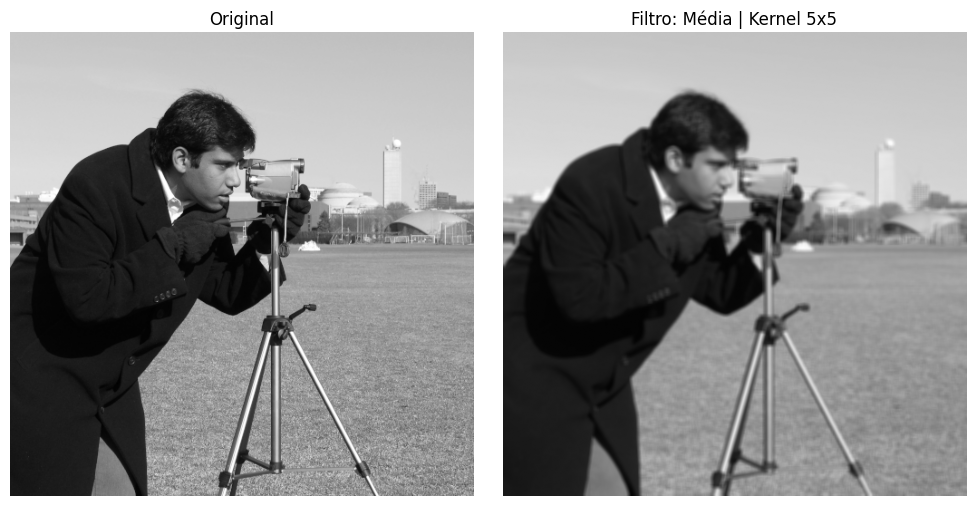

In [7]:
img_media = filtro_media(img, TAMANHO_KERNEL)
comparar(img, img_media, 'Média', TAMANHO_KERNEL)

###Mediana

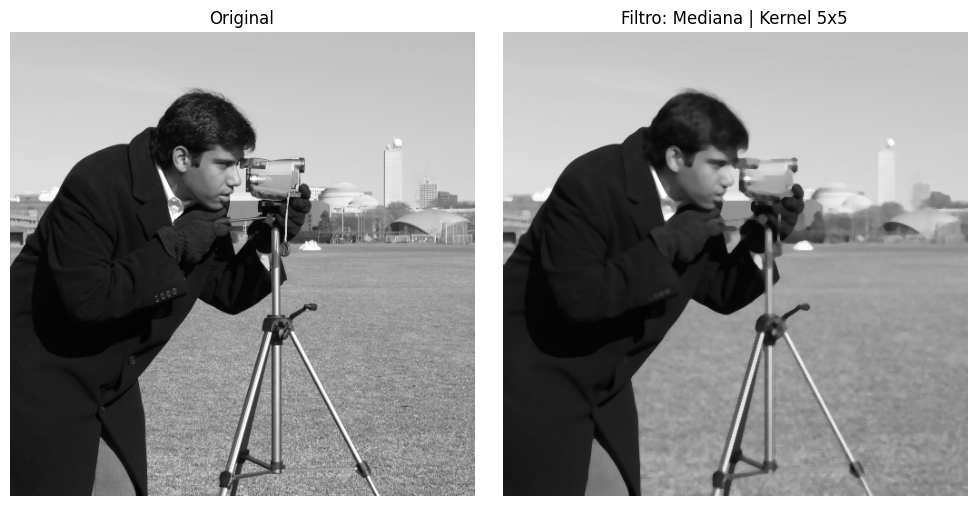

In [8]:
img_mediana = filtro_mediana(img, TAMANHO_KERNEL)
comparar(img, img_mediana, 'Mediana', TAMANHO_KERNEL)

###  Moda

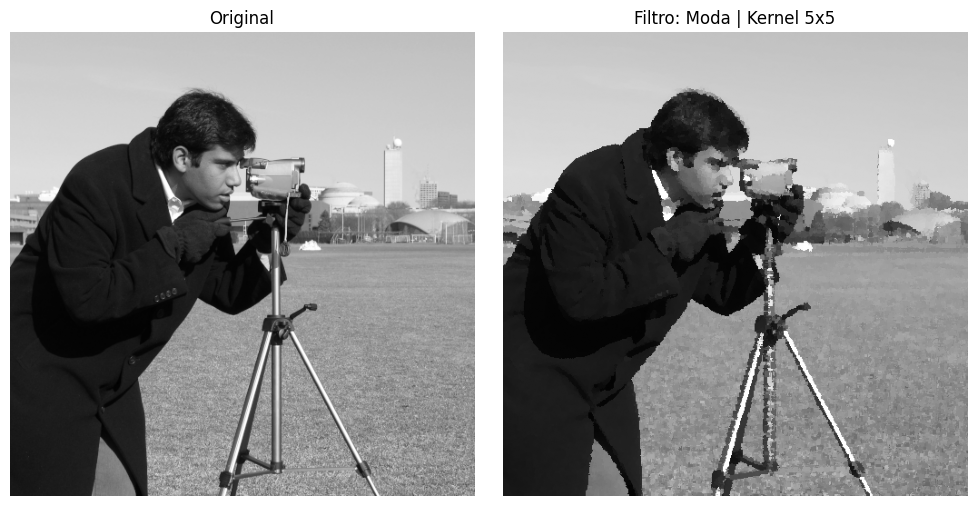

In [9]:
img_moda = filtro_moda(img, TAMANHO_KERNEL)
comparar(img, img_moda, 'Moda', TAMANHO_KERNEL)

### Máxima

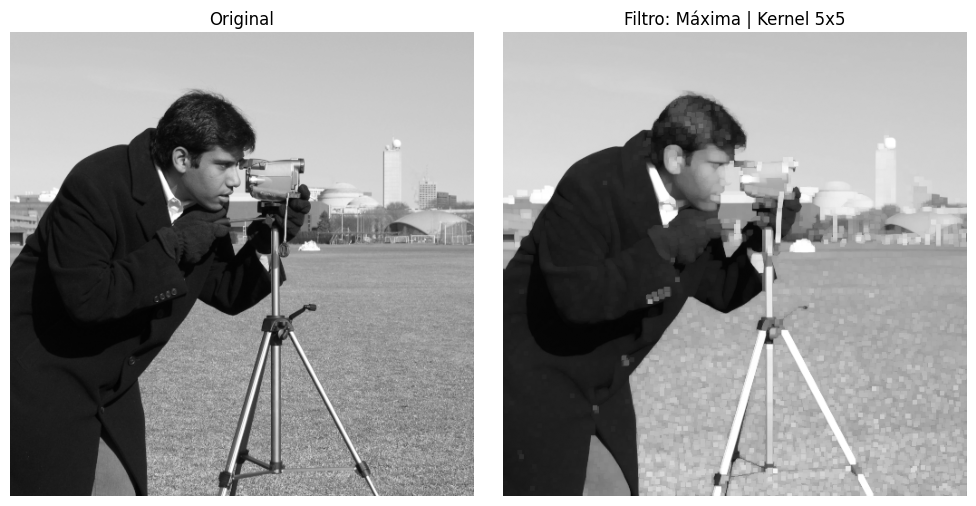

In [10]:
img_maxima = filtro_maxima(img, TAMANHO_KERNEL)
comparar(img, img_maxima, 'Máxima', TAMANHO_KERNEL)

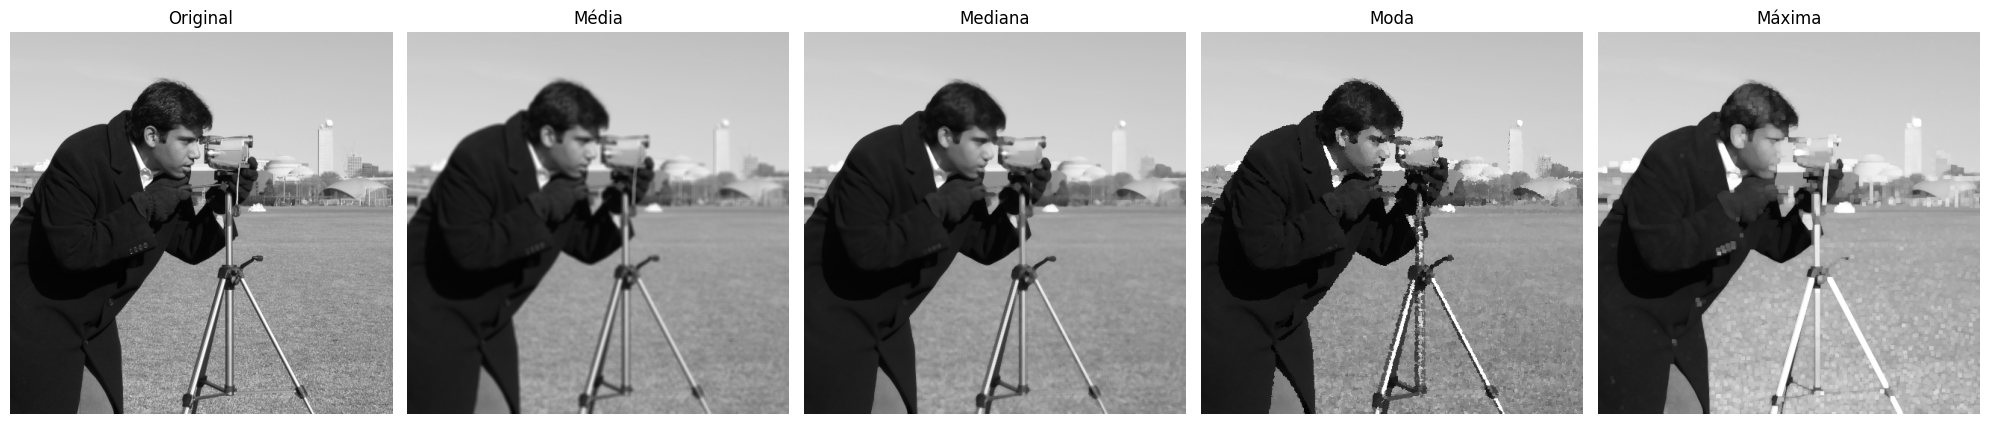

In [11]:
resultados = [
    ('Original', img),
    ('Média', img_media),
    ('Mediana', img_mediana),
    ('Moda', img_moda),
    ('Máxima', img_maxima),
]

fig, eixos = plt.subplots(1, 5, figsize=(20, 4.5))
for eixo, (titulo, imagem) in zip(eixos, resultados):
    eixo.imshow(imagem, cmap='gray', vmin=0, vmax=255)
    eixo.set_title(titulo)
    eixo.axis('off')
plt.tight_layout()
plt.show()